In [27]:
import pandas as pd

df = pd.read_csv('../data/raw/Churn_Modelling.csv')
print(df.shape)
df.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [28]:
print(df.columns.tolist())
df.info()
df['Exited'].value_counts(normalize=True)

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall churn rate
print(df['Exited'].value_counts(normalize=True))

# Churn rate by key categorical features
for col in ['Geography', 'Gender', 'NumOfProducts', 'IsActiveMember', 'HasCrCard']:
    print(f"\nChurn rate by {col}:")
    print(df.groupby(col)['Exited'].mean().round(3))

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Churn rate by Geography:
Geography
France     0.162
Germany    0.324
Spain      0.167
Name: Exited, dtype: float64

Churn rate by Gender:
Gender
Female    0.251
Male      0.165
Name: Exited, dtype: float64

Churn rate by NumOfProducts:
NumOfProducts
1    0.277
2    0.076
3    0.827
4    1.000
Name: Exited, dtype: float64

Churn rate by IsActiveMember:
IsActiveMember
0    0.269
1    0.143
Name: Exited, dtype: float64

Churn rate by HasCrCard:
HasCrCard
0    0.208
1    0.202
Name: Exited, dtype: float64


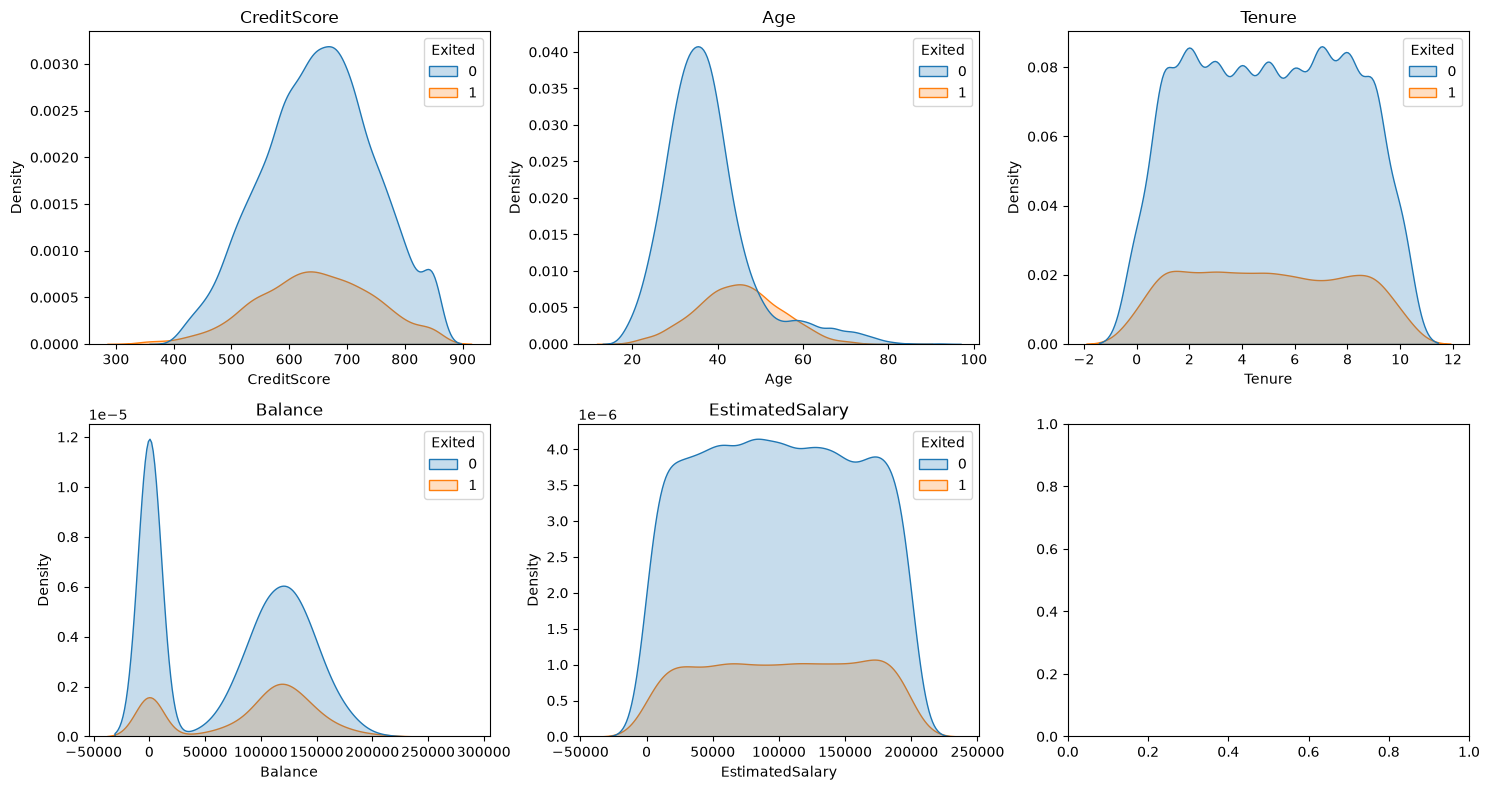

In [30]:
# Distributions of numeric features by churn status
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

for i, col in enumerate(numeric_cols):
    ax = axes[i // 3, i % 3]
    sns.kdeplot(data=df, x=col, hue='Exited', ax=ax, fill=True)
    ax.set_title(col)

plt.tight_layout()
plt.show()

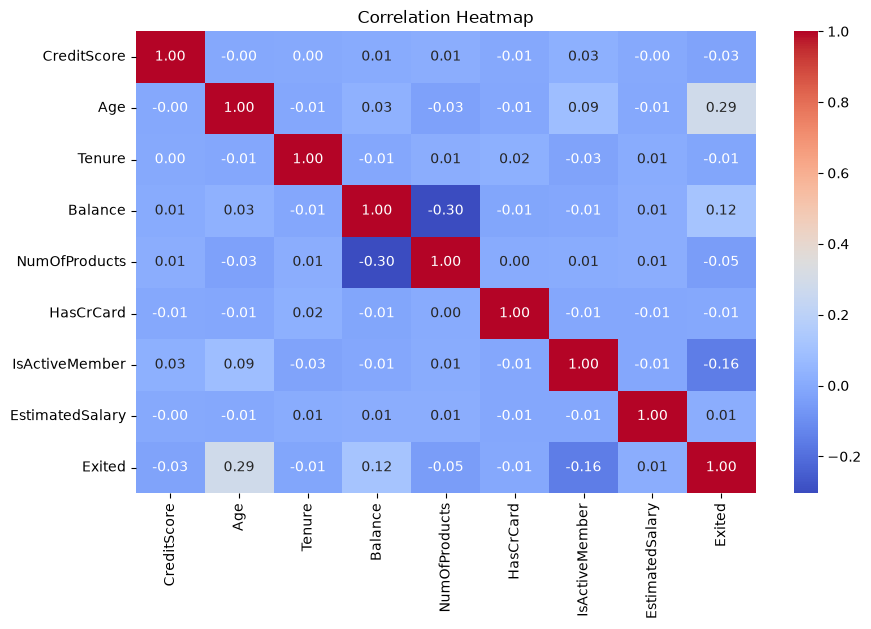

In [31]:
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include='number').drop(['RowNumber', 'CustomerId'], axis=1)
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

AgeGroup
(18, 30]     0.075
(30, 40]     0.121
(40, 50]     0.340
(50, 60]     0.562
(60, 100]    0.248
Name: Exited, dtype: float64


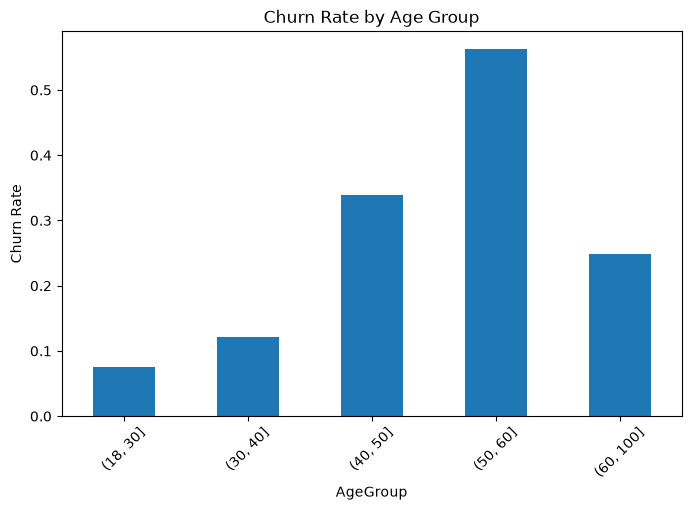

In [32]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[18,30,40,50,60,100])
print(df.groupby('AgeGroup')['Exited'].mean().round(3))

plt.figure(figsize=(8,5))
df.groupby('AgeGroup')['Exited'].mean().plot(kind='bar')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Age Group')
plt.xticks(rotation=45)
plt.show()

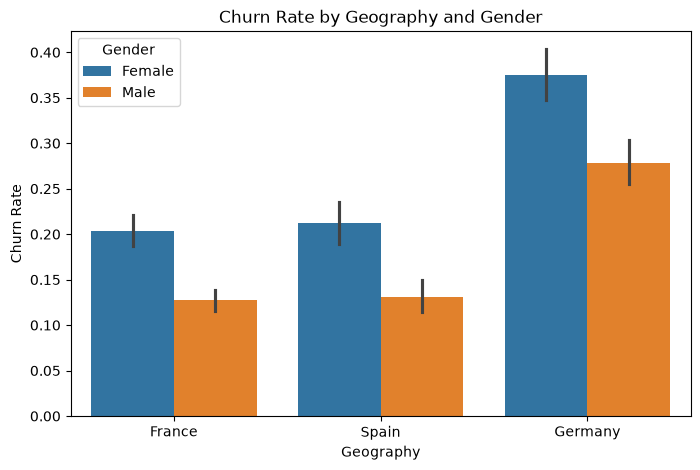

In [33]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Geography', y='Exited', hue='Gender')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Geography and Gender')
plt.show()

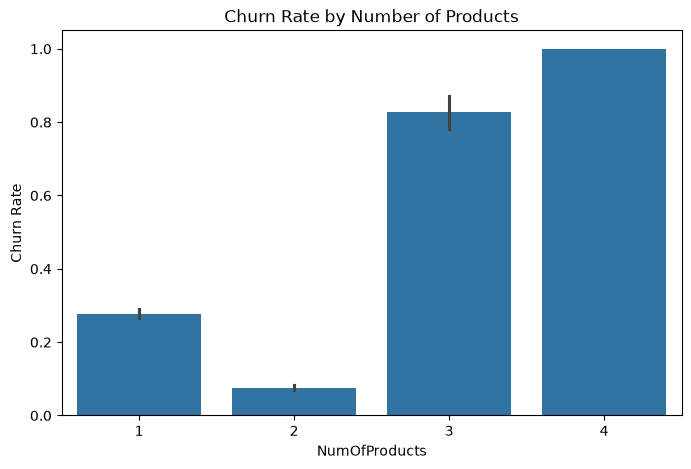

In [34]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='NumOfProducts', y='Exited')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Number of Products')
plt.show()

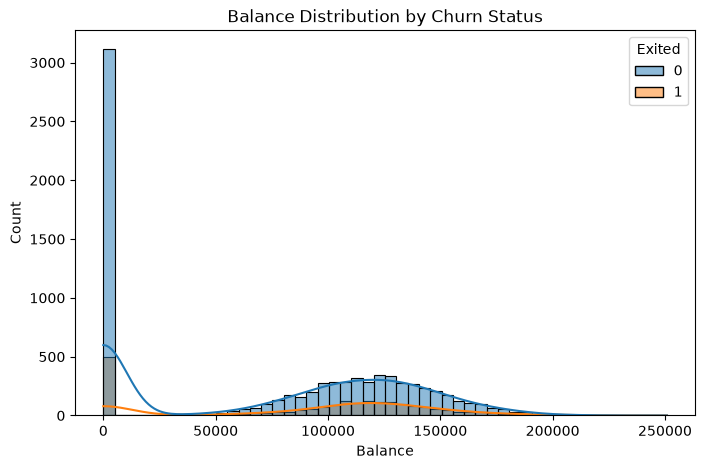

HasBalance
0    0.138
1    0.241
Name: Exited, dtype: float64


In [35]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Balance', hue='Exited', bins=50, kde=True)
plt.title('Balance Distribution by Churn Status')
plt.show()

df['HasBalance'] = (df['Balance'] > 0).astype(int)
print(df.groupby('HasBalance')['Exited'].mean().round(3))

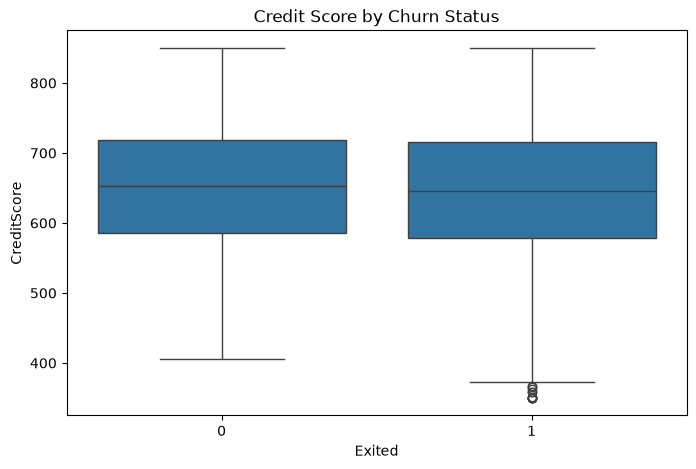

In [36]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Exited', y='CreditScore')
plt.title('Credit Score by Churn Status')
plt.show()

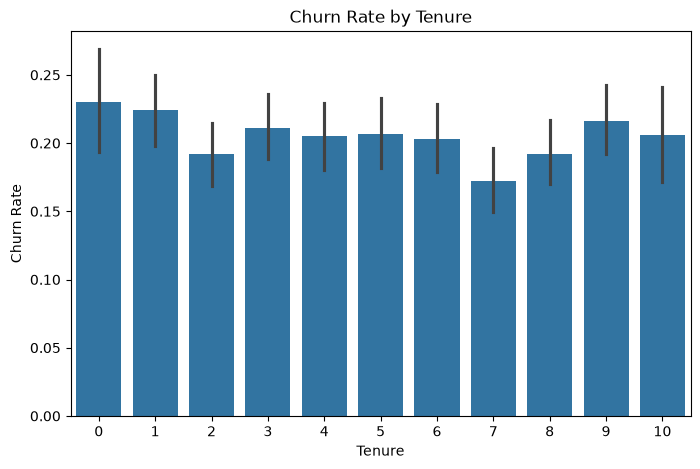

In [37]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Tenure', y='Exited')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Tenure')
plt.show()

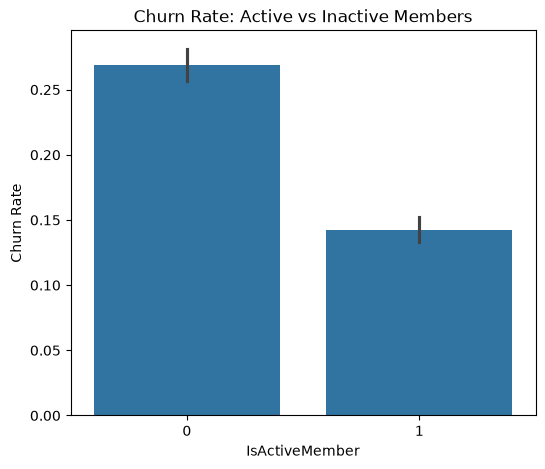

In [38]:
plt.figure(figsize=(6,5))
sns.barplot(data=df, x='IsActiveMember', y='Exited')
plt.ylabel('Churn Rate')
plt.title('Churn Rate: Active vs Inactive Members')
plt.show()

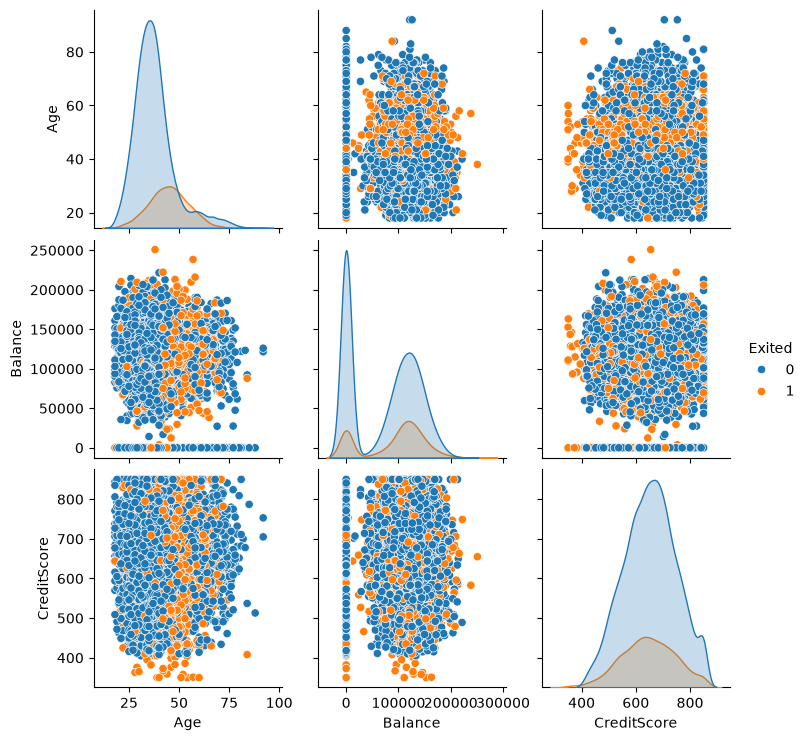

In [39]:
sns.pairplot(df[['Age', 'Balance', 'CreditScore', 'Exited']], hue='Exited', diag_kind='kde')
plt.show()

In [40]:
from scipy.stats import chi2_contingency

categorical_cols = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']

for col in categorical_cols:
    contingency = pd.crosstab(df[col], df['Exited'])
    chi2, p, dof, expected = chi2_contingency(contingency)
    print(f"{col}: chi2={chi2:.2f}, p-value={p:.4f}", "-> Significant" if p < 0.05 else "-> Not significant")

Geography: chi2=301.26, p-value=0.0000 -> Significant
Gender: chi2=112.92, p-value=0.0000 -> Significant
NumOfProducts: chi2=1503.63, p-value=0.0000 -> Significant
HasCrCard: chi2=0.47, p-value=0.4924 -> Not significant
IsActiveMember: chi2=242.99, p-value=0.0000 -> Significant


In [41]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

print(df.shape)
df.head()

(10000, 14)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,HasBalance,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,"(40, 50]",0,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,"(40, 50]",1,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,"(40, 50]",1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,"(30, 40]",0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,"(40, 50]",1,False,True,False


In [42]:
df = df.drop(['AgeGroup', 'HasBalance'], axis=1)
print(df.dtypes)

CreditScore            int64
Age                    int64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
Geography_Germany       bool
Geography_Spain         bool
Gender_Male             bool
dtype: object


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('Exited', axis=1)
y = df['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))

(8000, 11) (2000, 11)
Exited
0    0.79625
1    0.20375
Name: proportion, dtype: float64


In [44]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

strategies = {
    'Baseline (no handling)': (X_train, y_train, {}),
    'SMOTE': (X_train_smote, y_train_smote, {}),
    'Undersampling': (X_train_under, y_train_under, {}),
    'Class Weighting': (X_train, y_train, {'class_weight': 'balanced'})
}
print("strategies defined:", list(strategies.keys()))

strategies defined: ['Baseline (no handling)', 'SMOTE', 'Undersampling', 'Class Weighting']


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, average_precision_score
import pandas as pd

final_results = []

for strat_name, (Xt, yt, extra_params) in strategies.items():
    is_weighted = 'class_weight' in extra_params

    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced' if is_weighted else None),
        'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced' if is_weighted else None),
        'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss',
                                  scale_pos_weight=(yt==0).sum()/(yt==1).sum() if is_weighted else 1)
    }

    for model_name, model in models.items():
        if model_name == 'Logistic Regression':
            Xt_use = scaler.fit_transform(Xt)
            Xtest_use = scaler.transform(X_test)
        else:
            Xt_use, Xtest_use = Xt, X_test

        model.fit(Xt_use, yt)
        preds = model.predict(Xtest_use)
        probs = model.predict_proba(Xtest_use)[:, 1]

        final_results.append({
            'Strategy': strat_name,
            'Model': model_name,
            'AUC': roc_auc_score(y_test, probs),
            'PR-AUC': average_precision_score(y_test, probs),
            'F1': f1_score(y_test, preds),
            'Precision': precision_score(y_test, preds),
            'Recall': recall_score(y_test, preds)
        })

results_df = pd.DataFrame(final_results)
print(results_df.round(3))

                  Strategy                Model    AUC  PR-AUC     F1  \
0   Baseline (no handling)  Logistic Regression  0.775   0.479  0.284   
1   Baseline (no handling)        Random Forest  0.853   0.685  0.581   
2   Baseline (no handling)              XGBoost  0.833   0.665  0.583   
3                    SMOTE  Logistic Regression  0.731   0.465  0.468   
4                    SMOTE        Random Forest  0.839   0.619  0.586   
5                    SMOTE              XGBoost  0.824   0.643  0.580   
6            Undersampling  Logistic Regression  0.775   0.468  0.495   
7            Undersampling        Random Forest  0.853   0.649  0.594   
8            Undersampling              XGBoost  0.843   0.660  0.571   
9          Class Weighting  Logistic Regression  0.777   0.468  0.499   
10         Class Weighting        Random Forest  0.857   0.677  0.619   
11         Class Weighting              XGBoost  0.829   0.652  0.567   

    Precision  Recall  
0       0.589   0.187  
1 

Final Model — Random Forest + Class Weighting
AUC: 0.857
F1: 0.619
Precision: 0.629
Recall: 0.609


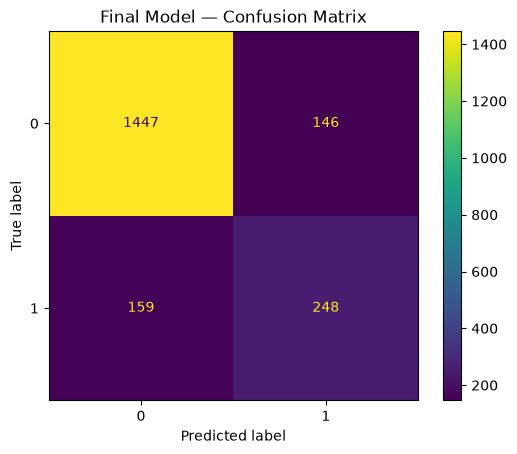

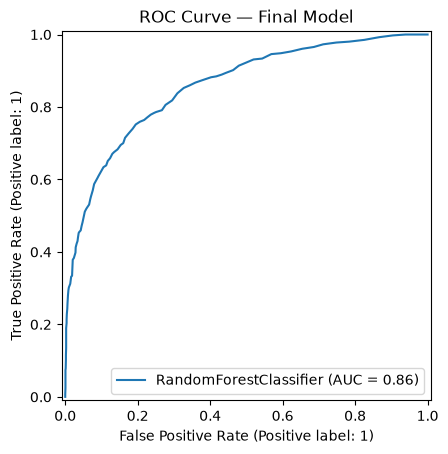

Model saved to model.pkl


In [46]:
final_model = RandomForestClassifier(random_state=42, class_weight='balanced')
final_model.fit(X_train, y_train)

preds = final_model.predict(X_test)
probs = final_model.predict_proba(X_test)[:, 1]

print("Final Model — Random Forest + Class Weighting")
print("AUC:", round(roc_auc_score(y_test, probs), 3))
print("F1:", round(f1_score(y_test, preds), 3))
print("Precision:", round(precision_score(y_test, preds), 3))
print("Recall:", round(recall_score(y_test, preds), 3))

# ADD THESE TWO BLOCKS HERE:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

ConfusionMatrixDisplay.from_predictions(y_test, preds)
plt.title('Final Model — Confusion Matrix')
plt.show()

RocCurveDisplay.from_estimator(final_model, X_test, y_test)
plt.title('ROC Curve — Final Model')
plt.show()

# THEN save:
import joblib
joblib.dump(final_model, '../model.pkl')
print("Model saved to model.pkl")

In [47]:
import shap

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

print(shap_values.shape)  # check shape first

(2000, 11, 2)


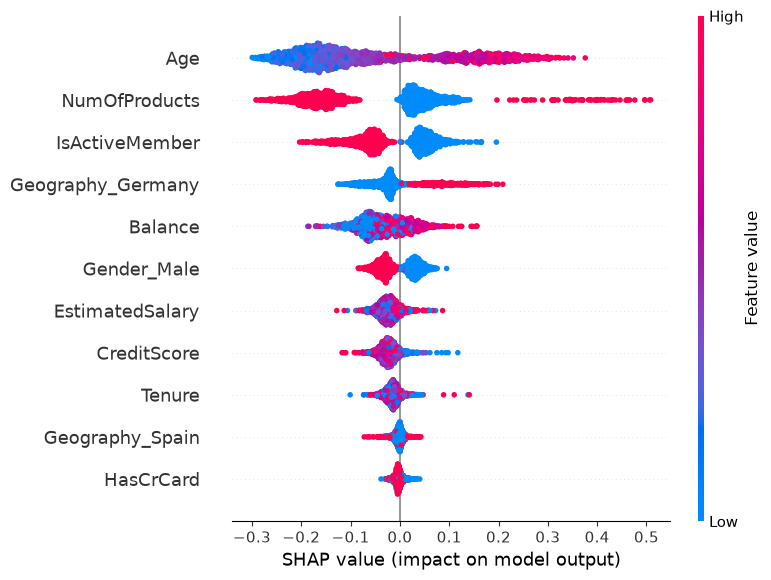

In [48]:
shap.summary_plot(shap_values[:, :, 1], X_test)